# EDA for Feature Discovery: Battery SOH under Unseen Conditions

**Goal:** decide *which features to use* for SOH regression / health classification, with an eye on the
project's real question: **do they still work for unseen cells and unseen operating profiles?**

**Unit of analysis.** SOH is only measured during the Reference Test Protocol (RTP), roughly every three weeks.
So one row = one RTP of one cell. Features come from (a) the RTP itself (health indicators measured on the cell),
(b) the usage history before it (throughput, time, temperature), and (c) the load-profile design parameters.


In [1]:
from pathlib import Path
import sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, h5py
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import load_test, read_info, step_blocks, C_NOM

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RAW = ROOT / "data" / "raw"

df_all = pd.read_csv(ROOT / "results" / "rtp_features.csv", dtype={"cell_id": str})
df = df_all[df_all.rtp_T_set == 25].dropna(subset=["SOH"]).reset_index(drop=True)
print("all RTP rows:", df_all.shape, "| RTP@25C rows with SOH:", df.shape)

all RTP rows: (422, 75) | RTP@25C rows with SOH: (306, 75)


## 1. What data do we have?

In [2]:
overview = (df.groupby(["cell_id", "profile"])
              .agg(n_rtp=("SOH", "size"), days=("days_since_start", "max"), EFC=("cum_EFC", "max"),
                   SOH_end=("SOH", "min"), T_set=("lp_T_set", "first"), CC=("lp_CC", "first"),
                   ADC=("lp_ADC", "first"), SoC=("lp_SoC", "first"), dSoC=("lp_dSoC", "first"))
              .round(1).reset_index())
display(overview)
print(f"{df.cell_id.nunique()} cells, {df.profile.nunique()} profiles, {len(df)} labelled rows")

,cell_id,profile,n_rtp,days,EFC,SOH_end,T_set,CC,ADC,SoC,dSoC
0,2_009,L03,21,530.8,1561.9,87.2,40.0,0.2,2.0,25.0,2.5
1,2_010,L03,21,530.8,1585.8,89.7,40.0,0.2,2.0,25.0,2.5
2,2_012,L35,22,530.8,1231.8,51.5,40.0,0.2,2.0,55.0,80.0
3,2_027,L208,22,530.8,434.4,92.8,0.0,0.0,1.5,55.0,2.5
4,2_030,L210,22,530.7,396.3,87.7,0.0,0.0,0.9,85.0,20.0
5,2_033,L211,22,530.7,412.0,70.2,0.0,0.0,1.5,40.0,50.0
6,2_058,L213,22,530.8,576.6,78.4,30.0,0.0,1.5,70.0,50.0
7,2_067,V212,21,509.9,707.3,47.0,NaN,NaN,NaN,NaN,NaN
8,2_076,L223,6,140.0,356.4,40.1,20.0,0.5,0.3,70.0,50.0
9,2_092,L202,22,530.8,8.3,88.2,45.0,0.0,0.0,15.0,0.0


15 cells, 14 profiles, 306 labelled rows


Each cell contributes only ~5–25 labelled points, and the profiles differ a lot
in how far the cells degrade. Calendar-ageing cells (L2xx with zero current) barely accumulate equivalent full cycles (EFC). That is
exactly why a random row split looks optimistic: neighbouring RTPs of the same cell are nearly identical.

## 2. Target sanity checks
### 2a. Why SOH must use RTP@25 °C only

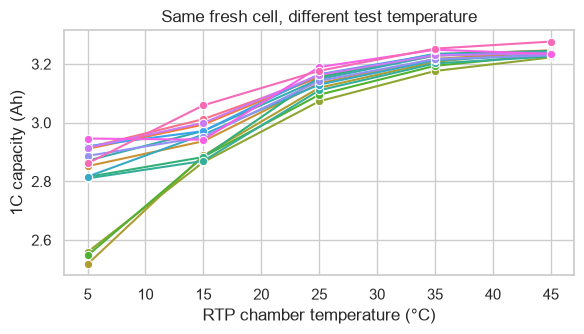

            mean    std
rtp_T_set              
5          2.810  0.145
15         2.946  0.058
25         3.141  0.031
35         3.221  0.020
45         3.239  0.013


In [3]:
init = df_all[df_all.rtp_index <= 1].copy()          # initial characterisation RTPs (before ageing)
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.lineplot(data=init, x="rtp_T_set", y="cap_1C_Ah", hue="cell_id", marker="o", ax=ax, legend=False)
ax.set(xlabel="RTP chamber temperature (°C)", ylabel="1C capacity (Ah)",
       title="Same fresh cell, different test temperature")
plt.tight_layout(); plt.savefig(FIG / "capacity_vs_test_temperature.png", dpi=150); plt.show()
print(init.groupby("rtp_T_set").cap_1C_Ah.agg(["mean", "std"]).round(3))

A fresh cell shows roughly 10 % less capacity at 5 °C than at 45 °C. If the RTP05/15/35/45 tests were mixed in, temperature
would look like "ageing". So: **SOH is defined on RTP@25 °C only**, and `rtp_T_set` must never be used as a feature for SOH.

### 2b. SOH trajectories: by time and by charge throughput

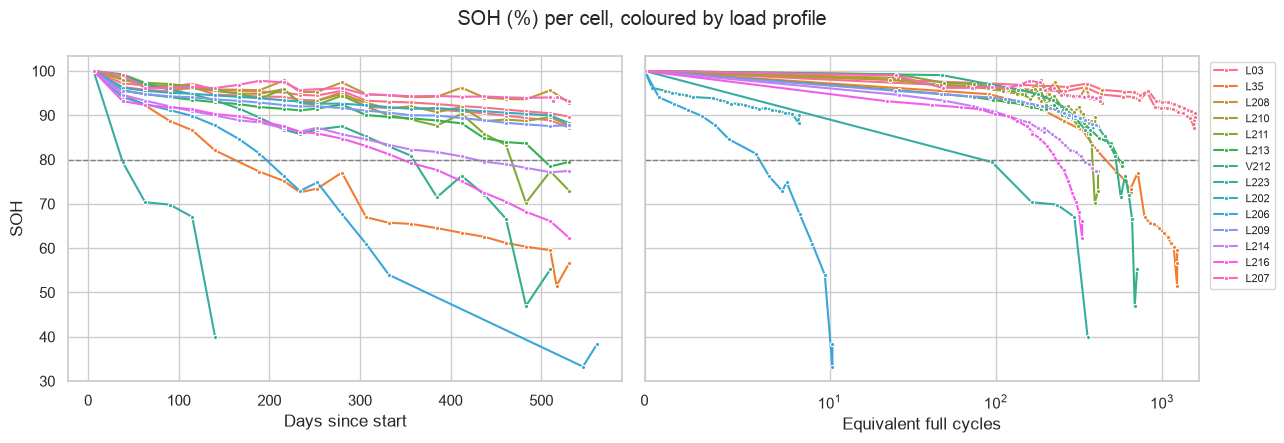

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, x, lab in [(axes[0], "days_since_start", "Days since start"), (axes[1], "cum_EFC", "Equivalent full cycles")]:
    sns.lineplot(data=df, x=x, y="SOH", hue="profile", units="cell_id", estimator=None, marker=".", ax=ax)
    ax.axhline(80, ls="--", c="grey", lw=1); ax.set_xlabel(lab)
axes[1].set_xscale("symlog", linthresh=10); axes[1].set_xlim(left=0)
axes[0].get_legend().remove(); axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.suptitle("SOH (%) per cell, coloured by load profile"); plt.tight_layout()
plt.savefig(FIG / "soh_trajectories.png", dpi=150); plt.show()

Observations to look for:
* **Same EFC, very different SOH across profiles.** Throughput alone does not explain degradation; operating conditions
  (temperature, SOC window) matter. This is the generalization challenge in one picture.
* Calendar cells lose capacity with ~0 EFC, so **time** must be a feature alongside throughput.
* Small upward bumps (capacity recovery after rests) are measurement noise that no model can predict.

### 2c. Target distribution and candidate health classes

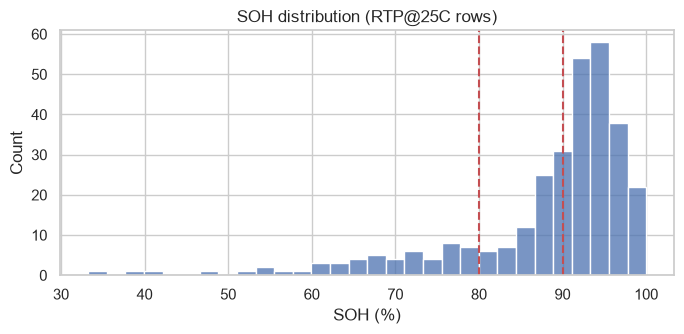

A: 90/80 {'Healthy': 187, 'Degraded': 66, 'EOL-risk': 53} | cells reaching EOL-risk: 8
B: 95/85 {'Healthy': 71, 'Degraded': 165, 'EOL-risk': 70} | cells reaching EOL-risk: 8


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(df.SOH, bins=30, ax=ax)
for t in (90, 80): ax.axvline(t, c="r", ls="--")
ax.set(title="SOH distribution (RTP@25C rows)", xlabel="SOH (%)")
plt.tight_layout(); plt.savefig(FIG / "soh_hist.png", dpi=150); plt.show()

bins_ = {"A: 90/80": [0, 80, 90, 200], "B: 95/85": [0, 85, 95, 200]}
for name, b in bins_.items():
    cls = pd.cut(df.SOH, b, labels=["EOL-risk", "Degraded", "Healthy"], right=False)
    print(name, cls.value_counts().reindex(["Healthy", "Degraded", "EOL-risk"]).to_dict(),
          "| cells reaching EOL-risk:", df.loc[cls == "EOL-risk", "cell_id"].nunique())

Pick the class thresholds from these counts. Common automotive practice is **80 % = end of life**. The dataset authors
used **70 %**, so most cells never reach it. If the EOL-risk class is tiny or comes from only 1–2 cells, either use
project-defined thresholds (option B) or report classification as exploratory. Recall on that class under
leave-cell-out would rest on almost no cells.

## 3. Looking at the raw signals: what changes as the cell ages?

example cell: 2_095


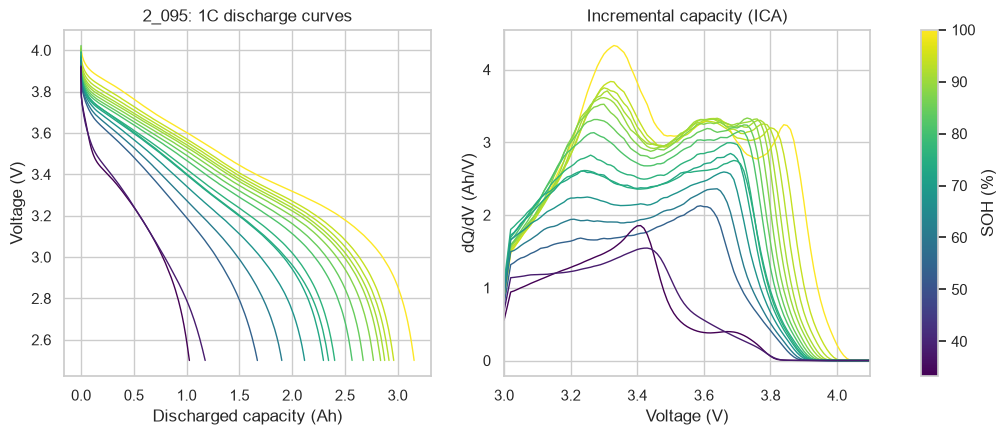

In [6]:
CELL = df.groupby("cell_id").SOH.min().idxmin()      # the most-degraded cell gives the clearest picture
print("example cell:", CELL)
with h5py.File(RAW / f"{CELL}.h5") as f:
    info = read_info(f)
    rtps = info[info.expname == "RTP25"]
    soh_map = df[df.cell_id == CELL].set_index("idtest").SOH
    curves = []
    for m in rtps.itertuples():
        if m.idtest not in soh_map.index: continue
        d = load_test(f["tests"][m.group]); b = step_blocks(d)
        full = b[(b.I.between(-1.1*C_NOM, -0.9*C_NOM)) & (b.V1 < 2.6) & (b.dur > 900)].iloc[-1]
        s = slice(int(full.a), int(full.b) + 1)
        curves.append((soh_map[m.idtest], d["dischargecap"][s] - d["dischargecap"][int(full.a)], d["voltage"][s]))

cmap = plt.cm.viridis
norm = plt.Normalize(min(c[0] for c in curves), 100)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for soh, Q, V in curves:
    axes[0].plot(Q, V, color=cmap(norm(soh)), lw=1)
    grid = np.arange(3.0, 4.15, 0.01)
    o = np.argsort(V); Vu, k = np.unique(V[o], return_index=True)
    ic = -np.gradient(np.interp(grid, Vu, Q[o][k]), 0.01)
    axes[1].plot(grid, np.convolve(ic, np.ones(5)/5, "same"), color=cmap(norm(soh)), lw=1)
axes[0].set(xlabel="Discharged capacity (Ah)", ylabel="Voltage (V)", title=f"{CELL}: 1C discharge curves")
axes[1].set(xlabel="Voltage (V)", ylabel="dQ/dV (Ah/V)", title="Incremental capacity (ICA)", xlim=(3.0, 4.1))
fig.colorbar(plt.cm.ScalarMappable(norm, cmap), ax=axes, label="SOH (%)")
plt.savefig(FIG / "discharge_and_ica_curves.png", dpi=150); plt.show()

* The discharge curve **shortens** (capacity loss) and **drops lower** (more polarization / resistance). That gives the
  partial-window capacity features (`dis1C_Q_3.8_3.5V`, `dis1C_t_to_3.6V_s`) and `dis1C_meanV`.
* The ICA peak **shrinks and shifts**, which motivates `ica_p1..p3_height` and `ica_p1..p3_V` (the ~3.3 V and ~3.85 V peaks change most). These are classic
  loss-of-active-material indicators.

## 4. Feature groups and the leakage question

Every RTP-derived feature is measured in the *same* test as the target. Some of them are just the capacity
measured another way, and using them would be target leakage. The features are grouped by **when and where they are
measured relative to the target**, which is the same split as the `role` column in
`results/preprocessed/data_dictionary.csv` (notebook 01):

| Group | Role | Measured |
|---|---|---|
| LEAKY (exclude) | never used | the target itself, or its numerator / denominator |
| Capacity measure (comparison) | leakage comparison only | charge or C/3-discharge capacity in the same test: capacity in disguise |
| Inside target test (comparison) | leakage comparison only | during the 1C discharges that define SOH, their rest, or the recharge *between* them |
| Pulse resistance | **main input** | 10 s pulses earlier in the same test, before the target discharges |
| Usage history | **main input** | before this test (time, throughput) |
| Previous load period | **main input** | the ageing period just before this test |
| Profile design | **main input** | the profile's designed settings |

In [7]:
R_COLS = [c for c in df.columns if c.startswith("R_")]
GROUPS = {
    "LEAKY (exclude)": ["cap_1C_Ah", "dis1C_energy_Wh", "cap_1C_spread_Ah", "cap_ref_Ah"],
    # comparison only: capacity measured another way in the same test
    "Capacity measure (comparison)": ["dis_C3_CC_Ah", "chg_CC_Ah", "chg_CC_time_s", "chg_CV_Ah", "chg_CC_fraction"],
    # comparison only: measured during the target 1C discharges, their rest, or the recharge between them
    "Inside target test (comparison)": ["dis1C_Q_3.8_3.5V", "dis1C_t_to_3.6V_s", "ica_area_3.4_3.8V", "dis1C_IRdrop_ohm",
                                        "dis1C_dT", "dis1C_meanV", "relax_dV_after_dis",
                                        "ica_p1_height", "ica_p1_V", "ica_p2_height", "ica_p2_V", "ica_p3_height", "ica_p3_V",
                                        "dis1C_Tstart", "rtp_T_mean", "chg_CC_V0", "chg_CV_time_s"],
    # main inputs
    "Pulse resistance": R_COLS,
    "Usage history": ["days_since_start", "rtp_index", "cum_dis_Ah", "cum_chg_Ah", "cum_EFC",
                      "cum_lp_days", "cum_lp_Tdays", "cum_lp_T_mean"],
    "Previous load period": [c for c in df.columns if c.startswith("prev_lp_")],
    "Profile design": ["lp_T_set", "lp_CC", "lp_ADC", "lp_PDC", "lp_F", "lp_SoC", "lp_dSoC"],
}
GROUPS = {g: [c for c in cols if c in df.columns] for g, cols in GROUPS.items()}
group_of = {c: g for g, cols in GROUPS.items() for c in cols}
COMPARISON_GROUPS = ["Capacity measure (comparison)", "Inside target test (comparison)"]
MAIN_GROUPS = ["Pulse resistance", "Usage history", "Previous load period", "Profile design"]
MAIN_FEATS = [c for g in MAIN_GROUPS for c in GROUPS[g]]
COMPARISON_FEATS = [c for g in COMPARISON_GROUPS for c in GROUPS[g]]
FEATS = MAIN_FEATS + COMPARISON_FEATS        # everything except LEAKY is screened; only MAIN_FEATS can be recommended

# Same definition as notebook 01's data dictionary (run 01 first to get the file)
DICT = ROOT / "results" / "preprocessed" / "data_dictionary.csv"
if DICT.exists():
    role = pd.read_csv(DICT, index_col="column").role
    assert set(MAIN_FEATS) == set(role[role == "input"].index) - {"schedule"}, "main inputs differ from notebook 01"
    assert set(COMPARISON_FEATS) == set(role[role == "comparison"].index), "comparison features differ from notebook 01"
    assert set(GROUPS["LEAKY (exclude)"]) == set(role[role == "leaky"].index), "leaky features differ from notebook 01"
    print("Groups match the roles in", DICT.relative_to(ROOT))
else:
    print("(data_dictionary.csv not found; run notebook 01 to check the groups against it)")

print(pd.Series({g: len(c) for g, c in GROUPS.items()}).to_string())
print(f"\nmain inputs: {len(MAIN_FEATS)} | comparison only: {len(COMPARISON_FEATS)}")
miss = df[FEATS].isna().mean().mul(100).round(1)
print("\nFeatures with missing values (%):"); print(miss[miss > 0].sort_values(ascending=False).to_string() or "none")

Groups match the roles in results/preprocessed/data_dictionary.csv
LEAKY (exclude)                     4
Capacity measure (comparison)       5
Inside target test (comparison)    17
Pulse resistance                   15
Usage history                       8
Previous load period               12
Profile design                      7

main inputs: 42 | comparison only: 22

Features with missing values (%):
lp_ADC                6.9
lp_dSoC               6.9
lp_SoC                6.9
lp_F                  6.9
lp_T_set              6.9
lp_PDC                6.9
lp_CC                 6.9
prev_lp_days          4.9
prev_lp_I_dis_mean    4.9
prev_lp_dis_Ah        4.9
cum_lp_T_mean         4.9
prev_lp_V_max         4.9
prev_lp_V_mean        4.9
prev_lp_T_max         4.9
prev_lp_T_mean        4.9
prev_lp_chg_Ah        4.9
prev_lp_rest_frac     4.9
prev_lp_I_chg_mean    4.9
prev_lp_V_min         4.9
prev_lp_I_dis_peak    4.9
R_0p18C_10s_lowSOC    1.3
R_0p18C_n             1.3
R_0p18C_inst_mean    

* **Capacity measures** and **inside-target-test** features will dominate any ranking, because they are the capacity
  (or the voltage right after draining it) measured another way. They are screened below only to show that effect, and
  used in modelling only as a leakage comparison. This includes `chg_CC_V0` and `chg_CV_time_s`: they come from the C/2
  recharge that sits *between* the two 1C discharges whose average defines SOH.
* **Pulse resistances** are the most defensible measured features: short pulses before the target discharges, with no
  charge integrated over the full window.
* **Usage / profile features** require no health measurement at all. That is the hardest but most "unseen-conditions" relevant setting.
* `prev_lp_*` are missing for the first RTP@25 (no ageing yet), so impute with training-fold statistics or drop that row.

## 5. Univariate screening: pooled vs. within-cell correlation

In [8]:
def within_cell_spearman(col):
    vals = []
    for _, g in df.groupby("cell_id"):
        g = g[[col, "SOH"]].dropna()
        if len(g) >= 4 and g[col].nunique() > 1 and g.SOH.nunique() > 1:
            vals.append(spearmanr(g[col], g.SOH).statistic)
    return (np.nanmedian(vals) if vals else np.nan, np.mean(np.sign(vals) == np.sign(np.nanmedian(vals))) if vals else np.nan)

rows = []
X_mi = df[FEATS].fillna(df[FEATS].median())
mi = mutual_info_regression(X_mi, df.SOH, random_state=0)
for c, m in zip(FEATS, mi):
    sub = df[[c, "SOH"]].dropna()
    med, agree = within_cell_spearman(c)
    rows.append(dict(feature=c, group=group_of[c], pooled_spearman=spearmanr(sub[c], sub.SOH).statistic,
                     within_cell_median=med, sign_consistency=agree, mutual_info=m))
screen = pd.DataFrame(rows).set_index("feature")
screen["abs_pooled"] = screen.pooled_spearman.abs()
display(screen.sort_values("abs_pooled", ascending=False).round(3))

,group,pooled_spearman,within_cell_median,sign_consistency,mutual_info,abs_pooled
feature,,,,,,
chg_CC_time_s,Capacity measure (comparison),0.962,0.998,1.000,1.862,0.962
chg_CC_Ah,Capacity measure (comparison),0.961,0.998,1.000,1.867,0.961
dis1C_t_to_3.6V_s,Inside target test (comparison),0.954,0.991,1.000,1.520,0.954
R_1p13C_10s_soc55,Pulse resistance,-0.939,-0.983,1.000,1.404,0.939
R_1p35C_10s_soc55,Pulse resistance,-0.939,-0.982,1.000,1.312,0.939
...,...,...,...,...,...,...
dis1C_Tstart,Inside target test (comparison),-0.035,0.004,0.533,0.200,0.035
rtp_T_mean,Inside target test (comparison),-0.029,0.073,0.533,0.159,0.029
prev_lp_days,Previous load period,0.025,-0.130,0.733,0.166,0.025


How to read this table:
* `pooled_spearman` mixes **between-cell** and **within-cell** variation. Profile parameters can score high here just
  because some profiles degrade more, which says nothing about tracking a cell's own ageing.
* `within_cell_median` is the median Spearman correlation inside each cell (does the feature *track ageing*?).
  `sign_consistency` is the share of cells where the direction agrees.
* **A good generalizing feature has a strong within-cell correlation with the same sign in nearly every cell.**
  Features whose sign flips between cells (often resistance at different temperatures) are risky under unseen conditions.

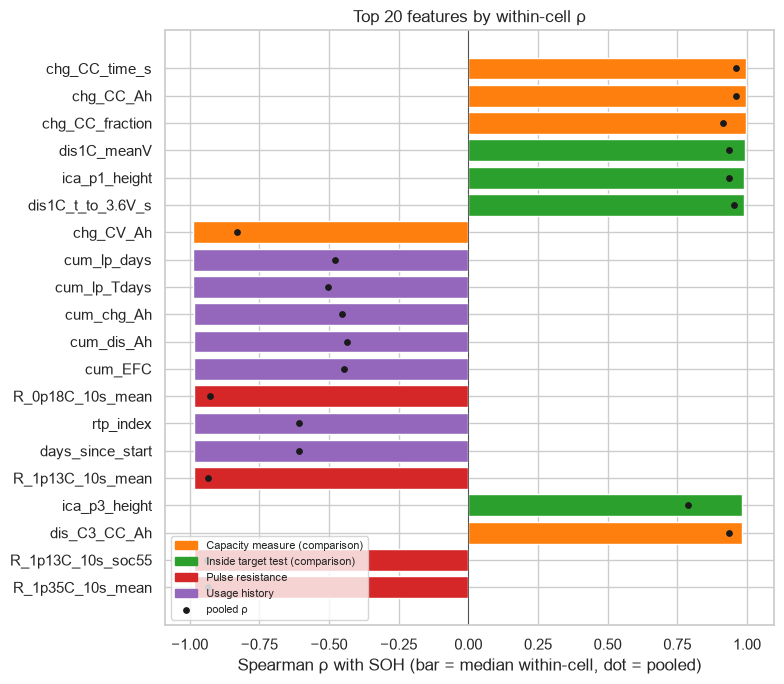

In [9]:
top = screen.dropna(subset=["within_cell_median"]).copy()
top["abs_within"] = top.within_cell_median.abs()
top = top.sort_values("abs_within", ascending=False).head(20)
fig, ax = plt.subplots(figsize=(8, 7))
pal = dict(zip(GROUPS, sns.color_palette("tab10", len(GROUPS))))
ax.barh(top.index[::-1], top.within_cell_median[::-1], color=[pal[g] for g in top.group[::-1]])
ax.scatter(top.pooled_spearman[::-1], top.index[::-1], c="k", s=15, zorder=3, label="pooled")
ax.axvline(0, c="k", lw=.5)
handles = [plt.Rectangle((0,0),1,1,color=pal[g]) for g in GROUPS if g in set(top.group)]
ax.legend(handles + [ax.collections[0]], [g for g in GROUPS if g in set(top.group)] + ["pooled ρ"], fontsize=8, loc="lower left")
ax.set(xlabel="Spearman ρ with SOH (bar = median within-cell, dot = pooled)", title="Top 20 features by within-cell ρ")
plt.tight_layout(); plt.savefig(FIG / "feature_screen_spearman.png", dpi=150); plt.show()

## 6. Redundancy between candidate features

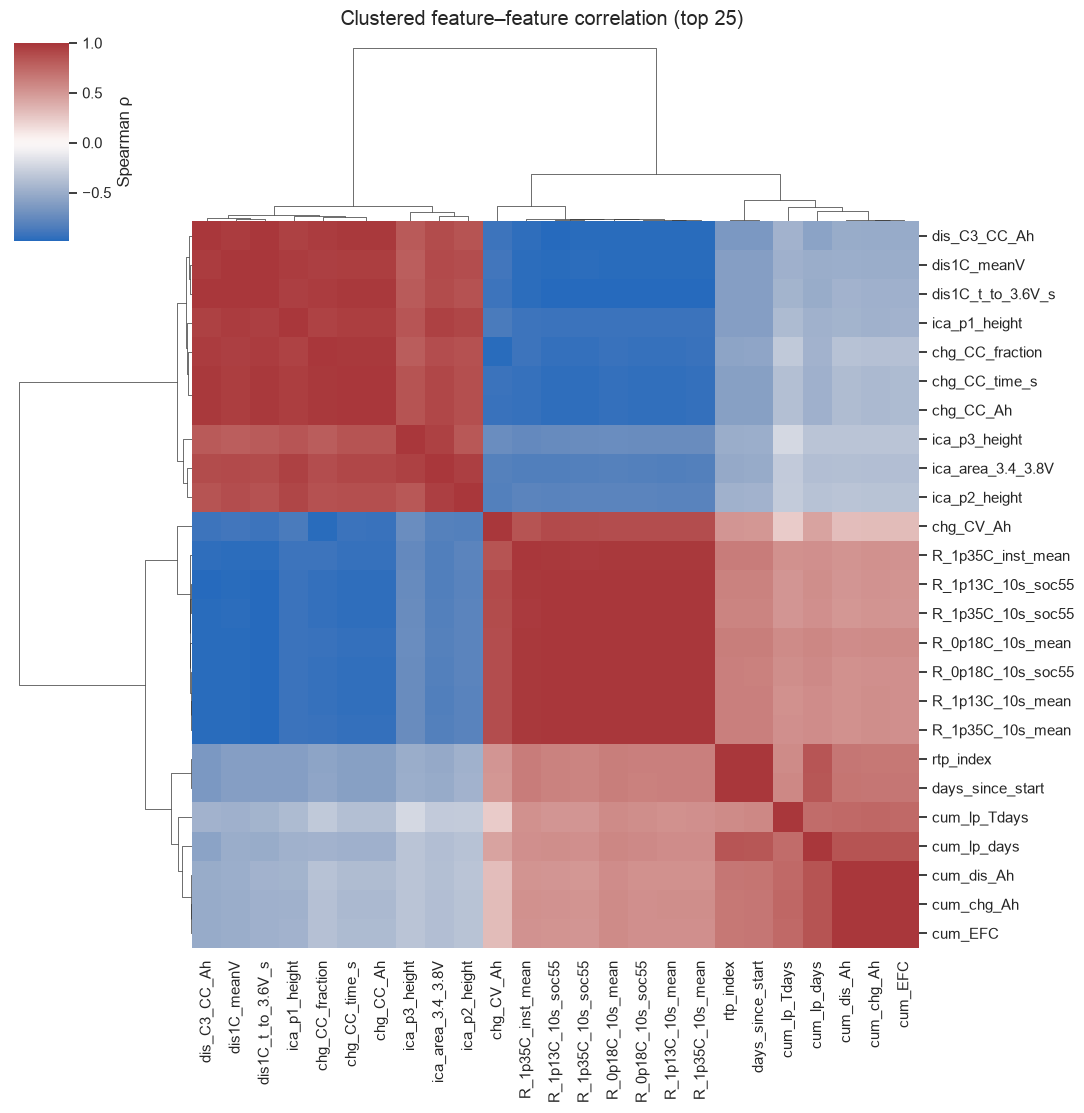

,level_0,level_1,rho
1,chg_CC_time_s,chg_CC_Ah,1.000
394,R_1p13C_10s_mean,R_1p35C_10s_mean,0.999
261,cum_dis_Ah,cum_EFC,0.999
236,cum_chg_Ah,cum_EFC,0.999
315,R_0p18C_10s_mean,R_1p13C_10s_mean,0.999
319,R_0p18C_10s_mean,R_1p35C_10s_mean,0.999
235,cum_chg_Ah,cum_dis_Ah,0.998
393,R_1p13C_10s_mean,R_1p13C_10s_soc55,0.997
320,R_0p18C_10s_mean,R_0p18C_10s_soc55,0.997
469,R_1p13C_10s_soc55,R_1p35C_10s_mean,0.996


In [10]:
cand = screen.dropna(subset=["within_cell_median"]).assign(a=lambda s: s.within_cell_median.abs()).sort_values("a", ascending=False).head(25).index
corr = df[cand].corr(method="spearman")
g = sns.clustermap(corr, cmap="vlag", center=0, figsize=(11, 11), annot=False, cbar_kws={"label": "Spearman ρ"})
g.fig.suptitle("Clustered feature–feature correlation (top 25)", y=1.01)
g.savefig(FIG / "feature_clustermap.png", dpi=150); plt.show()

# list pairs that are near-duplicates
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().rename("rho").reset_index()
            .query("abs(rho) > 0.95").sort_values("rho", key=abs, ascending=False))
display(pairs.head(20).round(3))

Blocks of |ρ| > 0.95 are **one feature in disguise**. Examples: all the `R_*` variants; the `cum_*` throughput and time
features within a profile; `chg_CC_time_s` and `chg_CC_Ah` (constant current, so time ∝ charge). Keep **one representative
per block**. That matters most for linear/ridge and SVR (multicollinearity), and less for random forest.

## 7. Which features survive an *unseen cell*? (group-aware screening)

Correlation isn't the same as generalization, so a quick model-based check follows. Random forest and ridge are trained on each
feature group with (a) a random row split and (b) **leave-cells-out** (GroupKFold by `cell_id`). The gap between
the two is the reliability question in the proposal. These are screening numbers, not final results.

In [11]:
def cv_scores(cols, groups_col="cell_id", n_splits=5, model="rf"):
    X, y, grp = df[cols], df.SOH.values, df[groups_col].values
    est = (make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(300, min_samples_leaf=2, random_state=0, n_jobs=-1))
           if model == "rf" else
           make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))))
    out = {}
    k = min(n_splits, len(np.unique(grp)))
    for name, cv, g in [("random", KFold(k, shuffle=True, random_state=0), None),
                        ("leave-cell-out", GroupKFold(k), grp)]:
        p = cross_val_predict(est, X, y, cv=cv, groups=g)
        out[f"MAE_{name}"] = mean_absolute_error(y, p); out[f"R2_{name}"] = r2_score(y, p)
    return out

sets = {
    "Usage history": GROUPS["Usage history"],
    "Usage + profile design": GROUPS["Usage history"] + GROUPS["Profile design"],
    "Usage + prev load period": GROUPS["Usage history"] + GROUPS["Previous load period"],
    "Pulse resistance": GROUPS["Pulse resistance"],
    "Pulse resistance + usage": GROUPS["Pulse resistance"] + GROUPS["Usage history"],
    "MAIN (all 4 input groups)": MAIN_FEATS,
    "Main + capacity measures [comparison]": MAIN_FEATS + GROUPS["Capacity measure (comparison)"],
    "Main + inside target test [comparison]": MAIN_FEATS + GROUPS["Inside target test (comparison)"],
}
res = []
base_mae = mean_absolute_error(df.SOH, np.full(len(df), df.SOH.mean()))
for name, cols in sets.items():
    for m in ["rf", "ridge"]:
        res.append(dict(feature_set=name, model=m, n_feats=len(cols), **cv_scores(cols, model=m)))
res = pd.DataFrame(res)
res["MAE_gap"] = res["MAE_leave-cell-out"] - res["MAE_random"]
print(f"Training-mean baseline MAE (in-sample, optimistic): {base_mae:.2f} SOH points")
display(res.round(3))

Training-mean baseline MAE (in-sample, optimistic): 7.86 SOH points


,feature_set,model,n_feats,MAE_random,R2_random,MAE_leave-cell-out,R2_leave-cell-out,MAE_gap
0,Usage history,rf,8,3.506,0.715,7.837,-0.270,4.331
1,Usage history,ridge,8,5.149,0.524,13.526,-5.921,8.377
2,Usage + profile design,rf,15,1.846,0.864,6.168,0.123,4.322
3,Usage + profile design,ridge,15,3.629,0.761,7.798,-0.301,4.169
4,Usage + prev load period,rf,20,1.721,0.862,5.496,0.261,3.775
5,Usage + prev load period,ridge,20,3.636,0.766,6.474,0.194,2.838
6,Pulse resistance,rf,15,2.203,0.885,2.791,0.832,0.588
7,Pulse resistance,ridge,15,2.287,0.907,2.988,0.842,0.701
8,Pulse resistance + usage,rf,23,1.760,0.914,2.918,0.798,1.158
9,Pulse resistance + usage,ridge,23,2.167,0.920,3.636,0.724,1.469


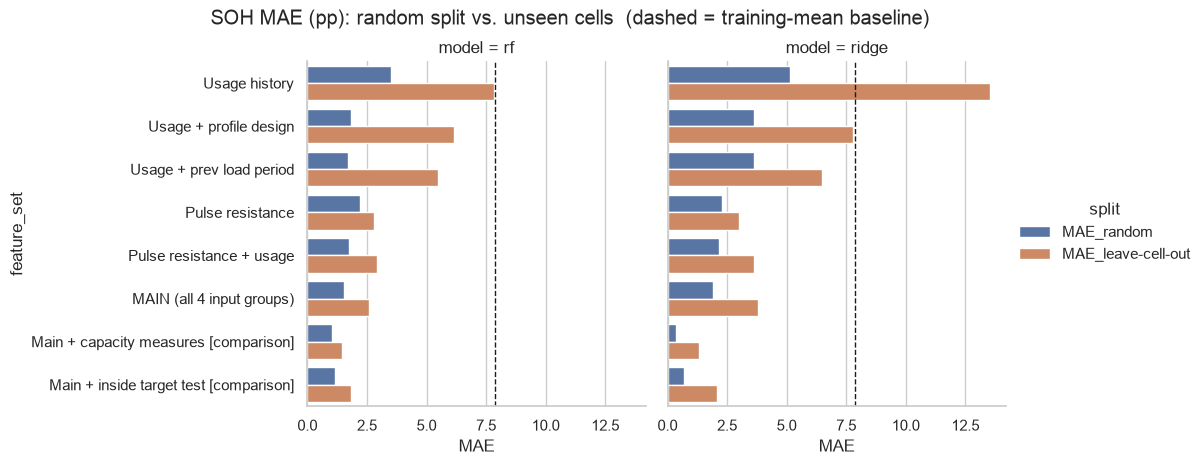

In [12]:
plot = res.melt(id_vars=["feature_set", "model"], value_vars=["MAE_random", "MAE_leave-cell-out"],
                var_name="split", value_name="MAE")
g = sns.catplot(data=plot, y="feature_set", x="MAE", hue="split", col="model", kind="bar", height=4.5, aspect=1.2)
for ax in g.axes.flat: ax.axvline(base_mae, c="k", ls="--", lw=1)
g.fig.suptitle("SOH MAE (pp): random split vs. unseen cells  (dashed = training-mean baseline)", y=1.03)
g.savefig(FIG / "random_vs_groupcv_by_featureset.png", dpi=150); plt.show()

### 7b. Permutation importance under leave-cell-out (main inputs only)

Run on the **main inputs** only. If the comparison features were included, they would take almost all the importance
(in the earlier version of this notebook the top four were `chg_CC_V0`, `chg_CC_time_s`, `chg_CC_Ah` and
`dis1C_t_to_3.6V_s`), which says nothing about the model we actually report.

,mean_MAE_increase,folds_positive,group
R_1p35C_10s_soc55,2.334,5.0,Pulse resistance
R_1p35C_inst_mean,0.772,4.0,Pulse resistance
R_1p13C_10s_soc55,0.573,5.0,Pulse resistance
R_1p13C_inst_mean,0.373,3.0,Pulse resistance
R_0p18C_10s_soc55,0.247,5.0,Pulse resistance
R_0p18C_10s_mean,0.173,3.0,Pulse resistance
prev_lp_I_dis_peak,0.111,2.0,Previous load period
R_1p35C_10s_mean,0.106,4.0,Pulse resistance
R_1p13C_10s_mean,0.059,3.0,Pulse resistance
R_0p18C_10s_lowSOC,0.058,3.0,Pulse resistance


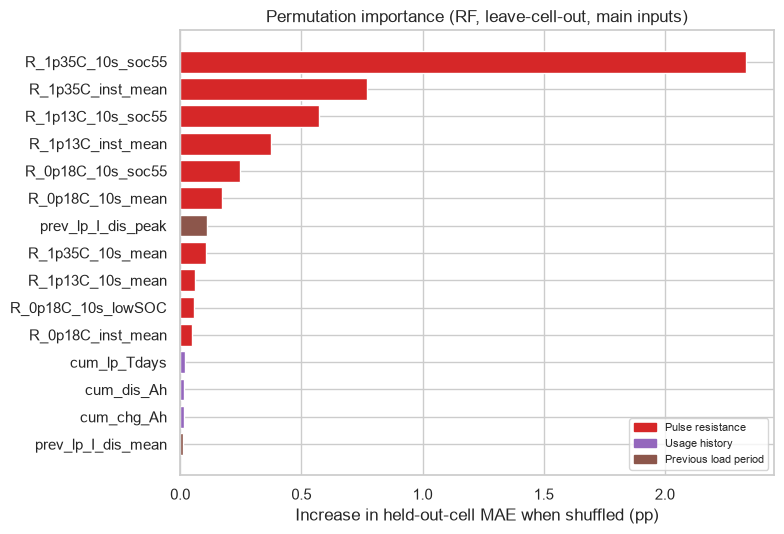

In [13]:
X, y, grp = df[MAIN_FEATS], df.SOH.values, df.cell_id.values
imp_rows = []
for tr, te in GroupKFold(min(5, df.cell_id.nunique())).split(X, y, grp):
    est = make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(300, min_samples_leaf=2, random_state=0, n_jobs=-1))
    est.fit(X.iloc[tr], y[tr])
    pi = permutation_importance(est, X.iloc[te], y[te], n_repeats=10, random_state=0, scoring="neg_mean_absolute_error")
    imp_rows.append(pd.Series(pi.importances_mean, index=MAIN_FEATS))
imp = pd.concat(imp_rows, axis=1)
imp_summary = pd.DataFrame({"mean_MAE_increase": imp.mean(1), "folds_positive": (imp > 0).sum(1),
                            "group": pd.Series(group_of)}).dropna(subset=["mean_MAE_increase"]) \
                .sort_values("mean_MAE_increase", ascending=False)
display(imp_summary.head(20).round(3))

top15 = imp_summary.head(15)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top15.index[::-1], top15.mean_MAE_increase[::-1], color=[pal[g] for g in top15.group[::-1]])
handles = [plt.Rectangle((0, 0), 1, 1, color=pal[g]) for g in MAIN_GROUPS if g in set(top15.group)]
ax.legend(handles, [g for g in MAIN_GROUPS if g in set(top15.group)], fontsize=8, loc="lower right")
ax.set(xlabel="Increase in held-out-cell MAE when shuffled (pp)", title="Permutation importance (RF, leave-cell-out, main inputs)")
plt.tight_layout(); plt.savefig(FIG / "permutation_importance_groupcv.png", dpi=150); plt.show()

Features with a high mean importance **and** positive importance in every fold are the ones to keep.
A feature that only helps in one fold is fitting a single cell's quirks.

Correlated features share importance: shuffling one member of a near-duplicate block (e.g. the `R_*` family or
`cum_EFC` ≈ `cum_dis_Ah`) costs little, because its twins still carry the information. So a low score for one member
of a block does not mean the block is unimportant; Section 6 lists the blocks.

## 8. Profile-level shift: are unseen operating conditions inside the training range?

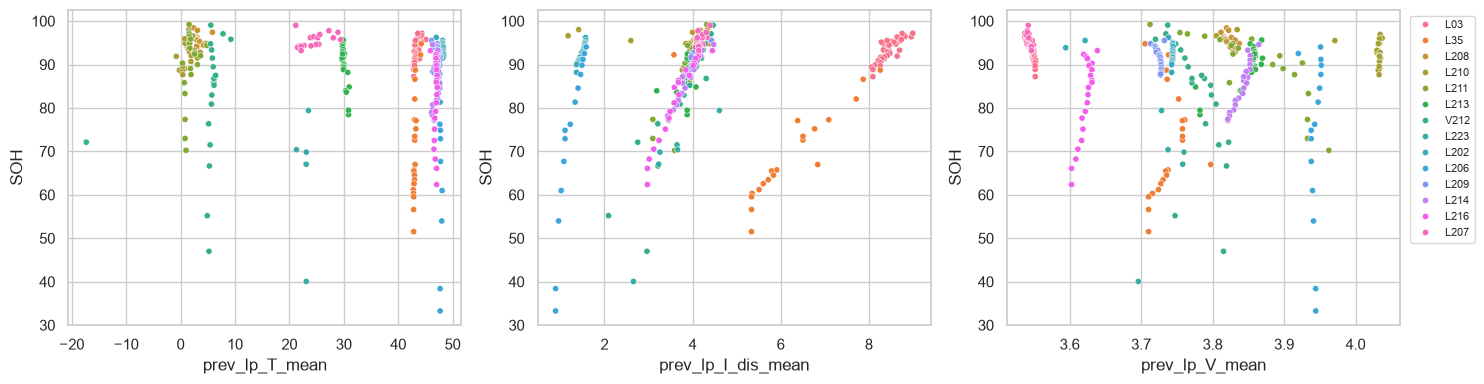

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, x in zip(axes, ["prev_lp_T_mean", "prev_lp_I_dis_mean", "prev_lp_V_mean"]):
    sns.scatterplot(data=df, x=x, y="SOH", hue="profile", ax=ax, s=20, legend=(ax is axes[-1]))
axes[-1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "operating_conditions_vs_soh.png", dpi=150); plt.show()

Each profile sits in its own corner of operating-condition space. When a whole profile is held out, a tree model
**cannot extrapolate** beyond the temperatures and currents it has seen. Choose held-out profiles that lie *inside* the
training range (interpolation) and, separately, at the edge (extrapolation), and report both. This gives the
"when does performance decrease" result the proposal asks for.

## 9. Summary: recommended feature set

In [15]:
summary = screen.join(imp_summary[["mean_MAE_increase", "folds_positive"]])
summary["role"] = np.where(summary.index.isin(MAIN_FEATS), "main input", "comparison only")
passes = ((summary.within_cell_median.abs() >= 0.6) & (summary.sign_consistency >= 0.8)) | \
         ((summary.mean_MAE_increase > 0) & (summary.folds_positive >= 4))
summary["keep"] = passes & (summary.role == "main input")
cols = ["group", "within_cell_median", "sign_consistency", "pooled_spearman", "mean_MAE_increase", "folds_positive"]

kept = summary[summary.keep].sort_values(["group", "mean_MAE_increase"], ascending=[True, False])
print(f"Recommended main inputs: {len(kept)} of {len(MAIN_FEATS)}")
print(kept.group.value_counts().to_string())
display(kept[cols].round(3))

excluded = summary[passes & (summary.role == "comparison only")]
print(f"\n{len(excluded)} comparison-only features would also pass the rule, but are NOT recommended (leakage):")
print(", ".join(excluded.index))

summary.round(4).to_csv(ROOT / "results" / "feature_screening_summary.csv")

Recommended main inputs: 23 of 42
group
Pulse resistance        12
Usage history            7
Previous load period     3
Profile design           1


,group,within_cell_median,sign_consistency,pooled_spearman,mean_MAE_increase,folds_positive
feature,,,,,,
prev_lp_I_dis_peak,Previous load period,0.961,1.0,0.461,0.111,2.0
prev_lp_I_dis_mean,Previous load period,0.901,1.0,0.405,0.013,2.0
prev_lp_I_chg_mean,Previous load period,0.948,1.0,0.135,-0.015,2.0
lp_F,Profile design,NaN,NaN,-0.114,0.000,4.0
R_1p35C_10s_soc55,Pulse resistance,-0.982,1.0,-0.939,2.334,5.0
R_1p35C_inst_mean,Pulse resistance,-0.973,1.0,-0.930,0.772,4.0
R_1p13C_10s_soc55,Pulse resistance,-0.983,1.0,-0.939,0.573,5.0
R_1p13C_inst_mean,Pulse resistance,-0.960,1.0,-0.919,0.373,3.0
R_0p18C_10s_soc55,Pulse resistance,-0.982,1.0,-0.936,0.247,5.0



17 comparison-only features would also pass the rule, but are NOT recommended (leakage):
dis_C3_CC_Ah, chg_CC_Ah, chg_CC_time_s, chg_CV_Ah, chg_CC_fraction, dis1C_Q_3.8_3.5V, dis1C_t_to_3.6V_s, ica_area_3.4_3.8V, dis1C_IRdrop_ohm, dis1C_meanV, ica_p1_height, ica_p2_height, ica_p2_V, ica_p3_height, ica_p3_V, chg_CC_V0, chg_CV_time_s


#Summary

DataSet: Our subset has 15 cells under 14 load profiles, with 306 labelled rows. Each row is one 25 °C reference test, and each cell has only 6–23 labels. Rows from one cell are strongly correlated, so the real sample size is 15 cells, not 306. Most profiles belong to a single cell, so unseen-cell and unseen-profile tests are nearly the same, and degradation varies widely (final SOH 33–93%).

Target Variable:
SOH is measured only at 25 °C, because test temperature changes capacity by about 13%.
Health classes: Healthy (above 90%), Degraded (80–90%), and EOL-risk (below 80%).
Class counts are 187, 66, and 53, and the EOL-risk class comes from only 8 cells.

Findings:

 Ageing depends on operating conditions, not just usage, at 45 °C, a cell held at 95 % SoC (L206) fell to 33 % SOH with almost no cycling, while one held at 15 % SoC (L202) stayed near 88 %
 Seven features leak the target and were removed(peak discharge current: 7.2 % → 1.2 %; mean charge current: 13.3 % → 1.6 %).
 Features were grouped by what must be measured to obtain them.
 Within-cell correlation is a better guide than pooled correlation.
 Features are split into main inputs (pulse resistance, usage history, previous load period, profile design: 42) and comparison-only features measured inside the target test or capacity in disguise (22), the same roles as notebook 01.
 Selected 23 of the 42 main inputs: a feature is kept if it tracks ageing consistently (|within-cell ρ| ≥ 0.6 with the same sign in ≥ 80 % of cells) or improves held-out-cell error when shuffled (positive in ≥ 4 of 5 folds). These are 12 pulse-resistance, 7 usage-history, 3 previous-load-period and 1 profile-design feature. 17 comparison features would also pass the rule but are excluded as leakage.
 Leakage check (random forest, leave-cell-out MAE): main inputs 2.59 pp; adding the capacity measures drops it to 1.47 pp, and adding the inside-target-test features to 1.84 pp. That gap is how much the comparison features would flatter the results.
 Five profiles, L206, L214, L210, L202 and L207 fall outside the range the other profiles cover, in temperature, voltage, rest time or minimum SOH.



